# Polynomial Regression Using Different Optimization Algorithms

In [1]:
!pip install ucimlrepo

## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading

In [3]:
try:
    # Primary source: UCI (internet)
    auto_mpg = fetch_ucirepo(id=9)
    X_data = auto_mpg.data.features
    y_data = auto_mpg.data.targets

    df = X_data.copy()
    df["mpg"] = y_data["mpg"]

    print("Loaded from UCI (internet)")

except Exception as e:
    # Backup source: Kaggle Dataset
    print("UCI failed, loading Kaggle backup:", e)

    import os

    for root, dirs, files in os.walk("/kaggle/input"):
        if "auto-mpg.data" in files:
            backup_path = os.path.join(root, "auto-mpg.data")
            break

    df = pd.read_csv(
        backup_path,
        names=["mpg", "cylinders", "displacement", "horsepower",
               "weight", "acceleration", "model_year", "origin", "car_name"],
        na_values="?",
        sep=r"\s+",
        skipinitialspace=True
    )

df = df[["horsepower", "mpg"]]

df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["mpg"] = pd.to_numeric(df["mpg"], errors="coerce")

display(df.head())
print("Dataset shape:", df.shape)

Loaded from UCI (internet)


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


Dataset shape: (398, 2)


## 3. Exploratory Data Analysis (EDA)

In [4]:
# Dataset Information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         398 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB

Statistical Summary:


,horsepower,mpg
count,392.000000,398.000000
mean,104.469388,23.514573
std,38.491160,7.815984
min,46.000000,9.000000
25%,75.000000,17.500000
50%,93.500000,23.000000
75%,126.000000,29.000000
max,230.000000,46.600000



Missing Values:
horsepower    6
mpg           0
dtype: int64


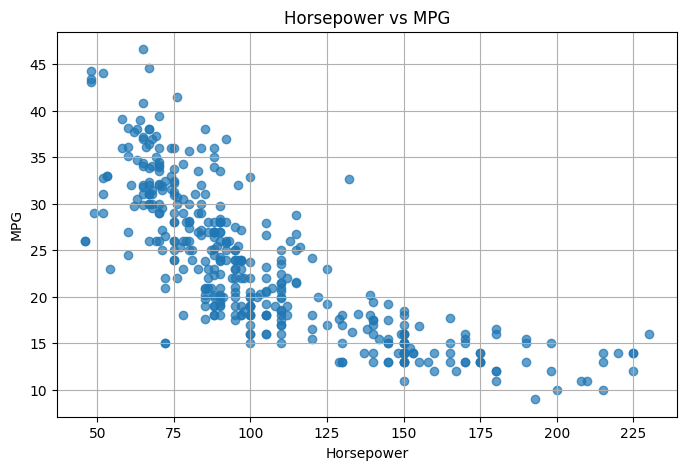

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(df["horsepower"], df["mpg"], alpha=0.7)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")

plt.grid(True)
plt.show()


## 4. Data Preprocessing

4.1 Separate Features and Target

4.2 Split Data into Training and Testing Sets

4.3 Handle Missing Values

4.4 Polynomial Feature Transformation

4.5 Feature Scaling

4.6 Add Bias Term

In [6]:

X = df[["horsepower"]].values
y = df[["mpg"]].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (398, 1)
y shape: (398, 1)


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 318
Testing samples: 80


In [8]:

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing values handled successfully!")


Missing values handled successfully!


In [9]:

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original features:", X_train.shape)
print("Polynomial features:", X_train_poly.shape)

print("\nFirst 5 polynomial samples:")
print(X_train_poly[:5])


Original features: (318, 1)
Polynomial features: (318, 2)

First 5 polynomial samples:
[[  150. 22500.]
 [   88.  7744.]
 [   68.  4624.]
 [   60.  3600.]
 [   95.  9025.]]


In [10]:

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Scale the target values too
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Feature scaling completed!")


Feature scaling completed!


In [11]:

# Add bias column to training and testing data

X_train_model = np.c_[
    np.ones((X_train_scaled.shape[0], 1)),
    X_train_scaled
]

X_test_model = np.c_[
    np.ones((X_test_scaled.shape[0], 1)),
    X_test_scaled
]

print("Training shape:", X_train_model.shape)
print("Testing shape:", X_test_model.shape)


Training shape: (318, 3)
Testing shape: (80, 3)


## 5. Model and Loss Function

In [12]:

# Initialize model parameters

n_features = X_train_model.shape[1]

initial_weights = np.zeros((n_features, 1))

print("Initial weights:")
print(initial_weights)


Initial weights:
[[0.]
 [0.]
 [0.]]


In [13]:

def compute_loss(X, y, weights):

    predictions = X @ weights

    #Mean Squared Error (MSE)
    loss = np.mean((predictions - y) ** 2)

    return loss


## 6. Optimization Algorithm

6.5 Adam

In [14]:

def compute_gradient(X, y, weights):

    m = len(y)

    predictions = X @ weights

    gradient = (2 / m) * X.T @ (predictions - y)

    return gradient


## 7. Train the Model

In [15]:
def train_adam(learning_rate=0.05, epochs=500,
               beta1=0.9, beta2=0.999, epsilon=1e-8):

    weights = np.zeros((X_train_model.shape[1], 1))

    m = np.zeros_like(weights)
    v = np.zeros_like(weights)

    loss_history = []

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        gradient = compute_gradient(
            X_train_model,
            y_train_scaled,
            weights
        )

        # Update biased first moment estimate
        m = beta1 * m + (1 - beta1) * gradient

        # Update biased second moment estimate
        v = beta2 * v + (1 - beta2) * (gradient ** 2)

        # Bias correction
        m_corrected = m / (1 - beta1 ** epoch)
        v_corrected = v / (1 - beta2 ** epoch)

        # Update weights
        weights -= (
            learning_rate * m_corrected
            / (np.sqrt(v_corrected) + epsilon)
        )

        epoch_loss = compute_loss(
            X_train_model,
            y_train_scaled,
            weights
        )

        loss_history.append(epoch_loss)

    training_time = time.time() - start_time

    return weights, loss_history, training_time

In [16]:
# Train using Adam
weights_adam, loss_history_adam, training_time_adam = train_adam()

# Print Results
print("Adam Final Loss:", loss_history_adam[-1])
print("Adam Training Time:", training_time_adam)
print("Adam Final Weights:")
print(weights_adam)

Adam Final Loss: 0.33675142452862766
Adam Training Time: 0.0238039493560791
Adam Final Weights:
[[-8.37586446e-15]
 [-2.20505338e+00]
 [ 1.46364717e+00]]


## 8. Visualizing Training Loss

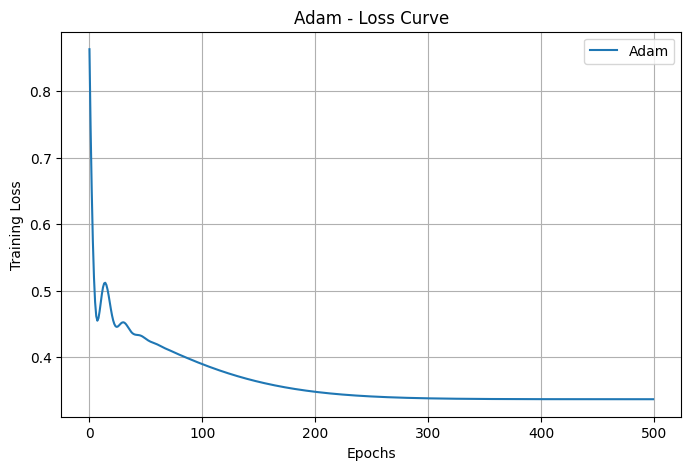

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history_adam, label="Adam")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Adam - Loss Curve")

plt.legend()
plt.grid(True)
plt.show()

## 9. Model Evaluation

In [18]:
# Predictions using Adam
y_pred_adam_scaled = X_test_model @ weights_adam

# Convert predictions back to original scale
y_pred_adam = scaler_y.inverse_transform(y_pred_adam_scaled)

# Evaluate Adam
print("Adam Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_adam))
print("MAE:", mean_absolute_error(y_test, y_pred_adam))
print("R2 Score:", r2_score(y_test, y_pred_adam))

Adam Evaluation:
MSE: 13.9683455448419
MAE: 2.925684163790642
R2 Score: 0.7402032834867956


## 10. Compare Results

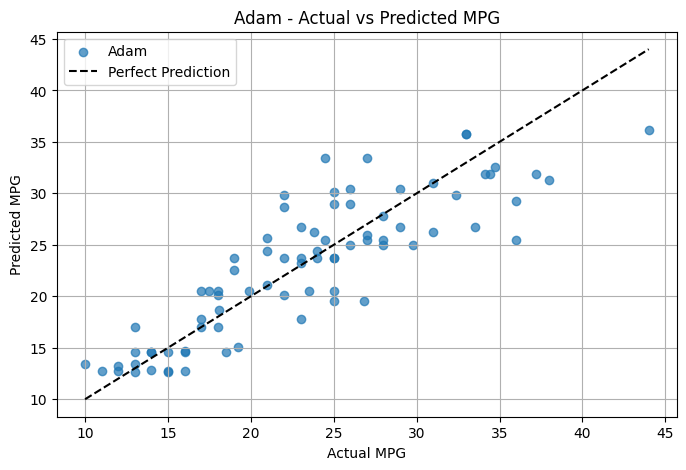

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_adam, label="Adam", alpha=0.7)

# Perfect prediction line
min_value = y_test.min()
max_value = y_test.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'k--',
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Adam - Actual vs Predicted MPG")

plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this notebook, Polynomial Regression (degree 2) was implemented using the Adam optimization algorithm to predict fuel efficiency (MPG) from horsepower. The same dataset and preprocessing steps were used as in the other notebooks to keep the comparison consistent.

Adam combines momentum (a moving average of gradients) with RMSprop-style adaptive step sizes (a moving average of squared gradients), plus bias correction for both moments. The learning rate was set to 0.05: with 0.01 and 500 epochs the model had not yet converged (training loss ~0.38 versus ~0.337 for the other methods), which made Adam look worse than it really is.

The model was evaluated with MSE, MAE and R² on the test set, and the loss curve and actual-vs-predicted plot were used to inspect the optimization. Re-run the notebook to see the final numbers; with a suitable learning rate Adam should reach essentially the same loss as the best methods, within far fewer epochs than plain GD.